# Week 6 · Topic 4 — Apply, Lambda and Finishing Up

**Box we are building: STORE + PROCESS, the whole job**

A `lambda` is a `def` you don't bother naming, for a one-line function you are
only going to use once — usually right inside `.apply()`.

> **Already know this?** Skip to the *Topic 4 Challenge*.

---
## 1. `.apply()` runs a function on every value in a column

Start with a normal function, the way Week 3 taught it.

In [ ]:
import pandas as pd

servers = pd.read_csv("examples/servers.csv")
servers["percent"] = (servers["used"] / servers["total"]) * 100

def classify(percent):
    if percent >= 100:
        return "OVER LIMIT"
    elif percent >= 90:
        return "WARNING"
    else:
        return "OK"

servers["status"] = servers["percent"].apply(classify)
print(servers)

### Your turn
Write your own single-argument function and `.apply()` it to the `used` column.

In [3]:
# your code here
import pandas as pf
servers=pd.read_csv("examples/servers.csv")
servers["percent"] = (servers["used"] / servers["total"]) * 100
def classify(percent):
    if percent>= 100:
        return"overlimit"
    elif percent>=90:
        return"warning"
    else:
        return"ok"
servers["status"]=servers["percent"].apply(classify)  
print(servers)  

       

  hostname region  used  total  percent     status
0   srv-01   east    87    100     87.0         ok
1   srv-02   east    45    100     45.0         ok
2   srv-03   west   120    100    120.0  overlimit
3   srv-04   west    93    100     93.0    warning
4   srv-05  north   101    100    101.0  overlimit
5   srv-06   east    60    100     60.0         ok
6   srv-07   west    30    100     30.0         ok
7   srv-08  north   110    100    110.0  overlimit
8   srv-09   east    95    100     95.0    warning
9   srv-10  north    55    100     55.0         ok


---
## 2. `lambda` - the same idea, written inline

`lambda parameters: expression` — that IS the whole function. Only one
expression allowed — no `if`/`elif`/`else` statements, no loops.

In [4]:
double = lambda x: x * 2
print(double(21))     # 42 - same as def double(x): return x * 2

42


```
def classify(p):                    lambda p: (
    if p >= 100:                        "OVER LIMIT" if p >= 100
        return "OVER LIMIT"             else "WARNING" if p >= 90
    elif p >= 90:                       else "OK"
        return "WARNING"             )
    else:
        return "OK"

same logic, same result - a block of statements vs one expression
```

### Your turn
Write `classify` as a lambda with a chained conditional, and check it gives the same result as the `def` version for every row.

In [5]:
# your code here
import pandas as pd
servers = pd.read_csv("examples/servers.csv")
servers["percent"] = (servers["used"] / servers["total"]) * 100
def classify(percent):
    if percent >= 90:
        return "High"
    elif percent >= 70:
        return "Medium"
    else:
        return "Low"
servers["status"] = servers["percent"].apply(classify)
classify_lambda = lambda x: "High" if x >= 90 else "Medium" if x >= 70 else "Low"
servers["status_lambda"] = servers["percent"].apply(classify_lambda)
print(servers[["region", "percent", "status", "status_lambda"]])
print(servers["status"] == servers["status_lambda"])

  region  percent  status status_lambda
0   east     87.0  Medium        Medium
1   east     45.0     Low           Low
2   west    120.0    High          High
3   west     93.0    High          High
4  north    101.0    High          High
5   east     60.0     Low           Low
6   west     30.0     Low           Low
7  north    110.0    High          High
8   east     95.0    High          High
9  north     55.0     Low           Low
0    True
1    True
2    True
3    True
4    True
5    True
6    True
7    True
8    True
9    True
dtype: bool


---
## 3. `.apply()` with a lambda, and `sort_values(key=...)`

lambda earns its place exactly here — a function small enough to write inline,
used exactly once, right where it is needed.

In [6]:
servers["status"] = servers["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
print(servers.sort_values("hostname", key=lambda col: col.str.lower()))

  hostname region  used  total  percent      status status_lambda
0   srv-01   east    87    100     87.0          OK        Medium
1   srv-02   east    45    100     45.0          OK           Low
2   srv-03   west   120    100    120.0  OVER LIMIT          High
3   srv-04   west    93    100     93.0     WARNING          High
4   srv-05  north   101    100    101.0  OVER LIMIT          High
5   srv-06   east    60    100     60.0          OK           Low
6   srv-07   west    30    100     30.0          OK           Low
7   srv-08  north   110    100    110.0  OVER LIMIT          High
8   srv-09   east    95    100     95.0     WARNING          High
9   srv-10  north    55    100     55.0          OK           Low


### Your turn
Use `.apply()` with a lambda to add a column `region_upper` — the `region` column, in capitals.

In [7]:
# your code here
servers["region_upper"] = servers["region"].apply(lambda x: x.upper())
print(servers)

  hostname region  used  total  percent      status status_lambda region_upper
0   srv-01   east    87    100     87.0          OK        Medium         EAST
1   srv-02   east    45    100     45.0          OK           Low         EAST
2   srv-03   west   120    100    120.0  OVER LIMIT          High         WEST
3   srv-04   west    93    100     93.0     WARNING          High         WEST
4   srv-05  north   101    100    101.0  OVER LIMIT          High        NORTH
5   srv-06   east    60    100     60.0          OK           Low         EAST
6   srv-07   west    30    100     30.0          OK           Low         WEST
7   srv-08  north   110    100    110.0  OVER LIMIT          High        NORTH
8   srv-09   east    95    100     95.0     WARNING          High         EAST
9   srv-10  north    55    100     55.0          OK           Low        NORTH


---
## 4. Summarising, saving, and a first chart

`describe()` for a quick overview, `.to_csv()` to save, and one chart — straight
off a DataFrame. In a notebook, calling `.plot()` shows the chart inline.

            used  total    percent
count   10.00000   10.0   10.00000
mean    79.60000  100.0   79.60000
std     30.05994    0.0   30.05994
min     30.00000  100.0   30.00000
25%     56.25000  100.0   56.25000
50%     90.00000  100.0   90.00000
75%     99.50000  100.0   99.50000
max    120.00000  100.0  120.00000


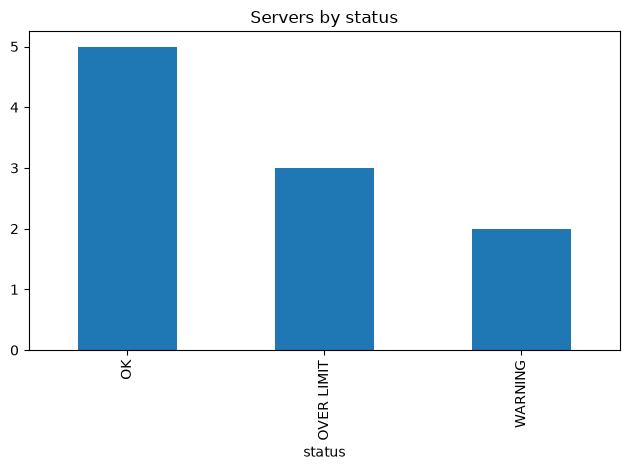

In [11]:
import matplotlib.pyplot as plt

print(servers.describe())

servers.to_csv("servers_report.csv", index=False)

servers["status"].value_counts().plot(kind="bar", title="Servers by status")
plt.tight_layout()
plt.show()

In [ ]:
%pip install matplotlib


### Your turn
Make a bar chart of servers per region instead of per status.

            used  total    percent
count   10.00000   10.0   10.00000
mean    79.60000  100.0   79.60000
std     30.05994    0.0   30.05994
min     30.00000  100.0   30.00000
25%     56.25000  100.0   56.25000
50%     90.00000  100.0   90.00000
75%     99.50000  100.0   99.50000
max    120.00000  100.0  120.00000


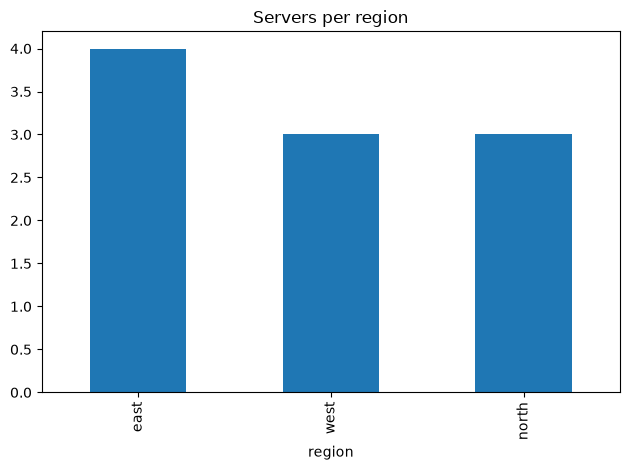

In [12]:
# your code here
# your code here
import matplotlib.pyplot as plt
print(servers.describe())
servers.to_csv("servers_report.csv", index=False)
servers["region"].value_counts().plot(kind="bar", title="Servers per region")
plt.tight_layout()
plt.show()

---
## Topic 4 Challenge

Load `servers.csv`, add `percent` and `status` (via `.apply()` with a lambda),
save the result to a new CSV, and produce one bar chart of the status counts.

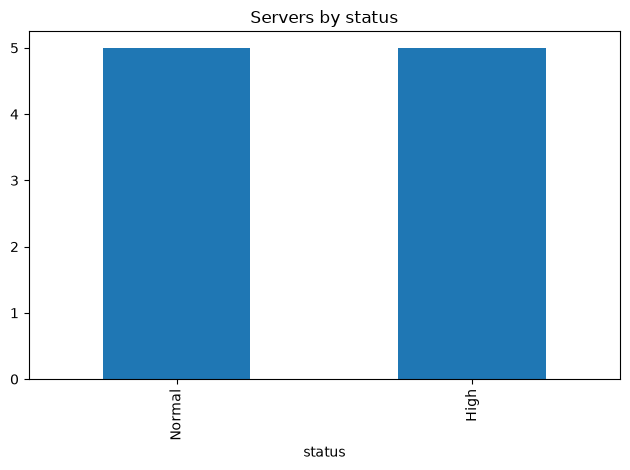

In [16]:
# your code here
import pandas as pd
import matplotlib.pyplot as plt
servers = pd.read_csv("examples/servers.csv")
servers["percent"] = (servers["used"] / servers["total"]) * 100
servers["status"] = servers["percent"].apply(
    lambda x: "High" if x >= 90 else "Normal"
)
servers.to_csv("servers_report.csv", index=False)
servers["status"].value_counts().plot(kind="bar", title="Servers by status")
plt.tight_layout()
plt.show()

---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | `df["clean_text"] = df["text"].apply(lambda t: t.strip().lower())` |
| **Cyber Security** | `df["flag"] = df["failed"].apply(lambda n: n >= 3)` |
| **IT** | `df.sort_values("hostname", key=lambda c: c.str.lower())` |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| a lambda with an `if` statement (not an expression) | `SyntaxError` | lambda only allows one expression — use chained `if/else`, or write a `def` |
| reusing the same lambda logic in three places | works, but repeats the logic three times | that is the sign you wanted a named function, not a lambda |
| forgetting `.apply()` and just writing `column.classify()` | `AttributeError` | `.apply(function)` runs your function on every value — the function itself is not a method on the column |
| calling `.plot()` in a plain script and seeing nothing | no chart appears | add `plt.show()` (script) — a notebook shows it automatically |

## Go deeper

`examples/01_apply_and_lambda.py` — apply, lambda syntax, chained conditionals, sort key
`examples/02_summarizing_saving_and_charting.py` — describe, to_csv, a first chart

---
## Recap

| You can now | Using |
|---|---|
| apply a function to a whole column | `column.apply(function)` |
| write a small inline function | `lambda x: expression` |
| choose lambda vs a named function | one-line, used once → lambda; reused or complex → `def` |
| get a quick overview | `.describe()` |
| save a result | `.to_csv(path, index=False)` |
| chart straight from a DataFrame | `.plot(kind=...)` |

**You now have all of CW1's toolkit.** Your mini-project this week closes it out.